# Práctica 4 — Punto 3: Regresión Logística

**Reconocimiento de patrones**

Este notebook sigue el orden de la guía:

1. Implementación de `RegresionLogistica` mediante descenso de gradiente batch.
2. Experimento 1: entrenamiento sin regularización.
3. Experimento 2: regularización L1 y L2.
4. Comparación de matrices de confusión, métricas y pesos `θ`.
5. Preguntas de análisis.

Se utiliza el dataset **Breast Cancer Wisconsin** indicado en la práctica. Los tres modelos compartirán exactamente la misma partición entrenamiento/prueba y los mismos datos normalizados para que la comparación sea justa.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)

np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 10)

print('Librerías cargadas correctamente.')

Librerías cargadas correctamente.


## Preparación del dataset

Se utiliza una partición 80/20 con `random_state=42` y estratificación para mantener una proporción similar de las dos clases. El escalador Z-score se ajusta únicamente con entrenamiento y luego transforma ambos conjuntos.

En el dataset de `scikit-learn`, la etiqueta `0` corresponde a **maligno** y la etiqueta `1` a **benigno**. Las métricas de precisión, recall y F1 se calcularán para la clase positiva `1` (benigno).

In [ ]:
cancer = load_breast_cancer()
X = cancer.data
y = cancer.target
nombres_caracteristicas = list(cancer.feature_names)
nombre_clases = {0: 'Maligno', 1: 'Benigno'}

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

escalador = StandardScaler()
X_train_norm = escalador.fit_transform(X_train)
X_test_norm = escalador.transform(X_test)

print(f'Muestras totales: {len(X)}')
print(f'Entrenamiento: {len(X_train)} ({len(X_train)/len(X):.0%})')
print(f'Prueba: {len(X_test)} ({len(X_test)/len(X):.0%})')
print(f'Características: {X.shape[1]}')
print('Distribución de clases en entrenamiento:', {nombre_clases[int(c)]: int((y_train == c).sum()) for c in np.unique(y_train)})
print('Distribución de clases en prueba:', {nombre_clases[int(c)]: int((y_test == c).sum()) for c in np.unique(y_test)})

Muestras totales: 569
Entrenamiento: 455 (80%)
Prueba: 114 (20%)
Características: 30
Distribución de clases en entrenamiento: {'Maligno': 170, 'Benigno': 285}
Distribución de clases en prueba: {'Maligno': 42, 'Benigno': 72}



## Implementación de `RegresionLogistica`

Se utiliza **descenso del gradiente batch**: cada actualización calcula el gradiente utilizando todas las muestras de entrenamiento. Se elige esta estrategia porque el dataset puede procesarse cómodamente en memoria y permite un entrenamiento sencillo de reproducir y analizar.

- `fit(X, y, lr, epocas, regularizacion, lam)`: entrena el modelo y aprende los parámetros θ.
- `predict_proba(X)`: devuelve la probabilidad estimada de pertenecer a la clase `1`, sin aplicar un umbral.
- `predict(X)`: convierte las probabilidades en clases mediante un umbral de `0.5`.
- Se registra la entropía cruzada binaria cada 100 épocas y se guarda el vector de parámetros θ para observar su evolución durante el entrenamiento.
- El sesgo θ₀ no se regulariza. Para L1, se añade al gradiente el término `(λ/m) · sign(θⱼ)`; para L2, se añade `(λ/m) · θⱼ`, donde `m` es el número de muestras de entrenamiento. En ambos casos, la penalización se aplica únicamente a los pesos asociados a las características.
- La pérdida registrada y graficada corresponde a la entropía cruzada binaria, sin sumar el término de penalización de la regularización, tal como se solicita en la práctica.


In [ ]:
import numpy as np

class RegresionLogistica:
    """Regresión logística binaria entrenada con descenso del gradiente batch."""

    def __init__(self):
        self.theta = None
        self.loss_history = []
        self.epochs_history = []
        self.theta_history = []
        self.regularizacion = None
        self.lam = 0.0

    @staticmethod
    def _sigmoid(z):
        # Evitar overflow numérico en la función exponencial.
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    @staticmethod
    def _binary_cross_entropy(y_true, probabilities):
        # Evitar logaritmos de cero.
        eps = 1e-12
        probabilities = np.clip(probabilities, eps, 1 - eps)

        return -np.mean(
            y_true * np.log(probabilities)
            + (1 - y_true) * np.log(1 - probabilities)
        )

    def fit(
        self,
        X,
        y,
        lr=0.1,
        epocas=4000,
        regularizacion=None,
        lam=0.0
    ):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()

        # Validación de los datos.
        if X.ndim != 2 or X.shape[0] != len(y):
            raise ValueError(
                'X debe ser una matriz y debe tener una etiqueta por fila.'
            )

        if not np.isin(y, [0, 1]).all():
            raise ValueError(
                'Esta implementación requiere etiquetas binarias 0 y 1.'
            )

        if lr <= 0:
            raise ValueError('lr debe ser mayor que cero.')

        if not isinstance(epocas, (int, np.integer)) or epocas < 1:
            raise ValueError('epocas debe ser un entero positivo.')

        if lam < 0:
            raise ValueError('lam debe ser mayor o igual que cero.')

        # Validar y estandarizar el nombre de la regularización.
        if regularizacion is not None:
            regularizacion = str(regularizacion).upper()

            if regularizacion not in ('L1', 'L2'):
                raise ValueError(
                    "regularizacion debe ser None, 'L1' o 'L2'."
                )

        # Añadir una columna de unos para representar el sesgo theta_0.
        X_bias = np.column_stack([
            np.ones(X.shape[0]),
            X
        ])

        # Inicializar los parámetros en cero.
        self.theta = np.zeros(X_bias.shape[1], dtype=float)

        # Reiniciar los historiales para cada entrenamiento.
        self.loss_history = []
        self.epochs_history = []
        self.theta_history = []

        self.regularizacion = regularizacion
        self.lam = float(lam)

        # Número de muestras de entrenamiento.
        m = len(y)

        # Descenso del gradiente batch.
        for epoca in range(1, epocas + 1):

            # 1. Calcular las probabilidades actuales.
            probabilidades = self._sigmoid(X_bias @ self.theta)

            # 2. Calcular el gradiente promedio de la entropía cruzada.
            gradiente = (
                X_bias.T @ (probabilidades - y)
            ) / m

            # 3. Aplicar regularización sin penalizar el sesgo theta_0.
            if regularizacion == 'L1':
                gradiente[1:] += (
                    self.lam / m
                ) * np.sign(self.theta[1:])

            elif regularizacion == 'L2':
                gradiente[1:] += (
                    self.lam / m
                ) * self.theta[1:]

            # 4. Actualizar los parámetros.
            self.theta -= lr * gradiente

            # 5. Registrar la pérdida y los pesos cada 100 épocas.
            if epoca % 100 == 0 or epoca == epocas:
                proba_actual = self._sigmoid(
                    X_bias @ self.theta
                )

                perdida = self._binary_cross_entropy(
                    y,
                    proba_actual
                )

                self.epochs_history.append(epoca)
                self.loss_history.append(perdida)
                self.theta_history.append(self.theta.copy())

        # Convertir el historial de pesos en una matriz NumPy.
        self.theta_history = np.asarray(self.theta_history)

        return self

    def predict_proba(self, X):
        """Retornar las probabilidades de pertenecer a la clase 1."""

        if self.theta is None:
            raise RuntimeError(
                'Primero debes entrenar el modelo con fit().'
            )

        X = np.asarray(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(1, -1)

        # Añadir la columna correspondiente al sesgo.
        X_bias = np.column_stack([
            np.ones(X.shape[0]),
            X
        ])

        return self._sigmoid(X_bias @ self.theta)

    def predict(self, X):
        """Convertir las probabilidades en clases usando umbral 0.5."""

        probabilidades = self.predict_proba(X)

        return (probabilidades >= 0.5).astype(int)


print('Clase RegresionLogistica implementada correctamente.')

Clase RegresionLogistica implementada correctamente.


## 3.1. Experimento 1 — Entrenamiento sin regularización

Se entrena el primer modelo con `regularizacion=None` y se grafica la entropía cruzada binaria frente al número de épocas para observar su convergencia.

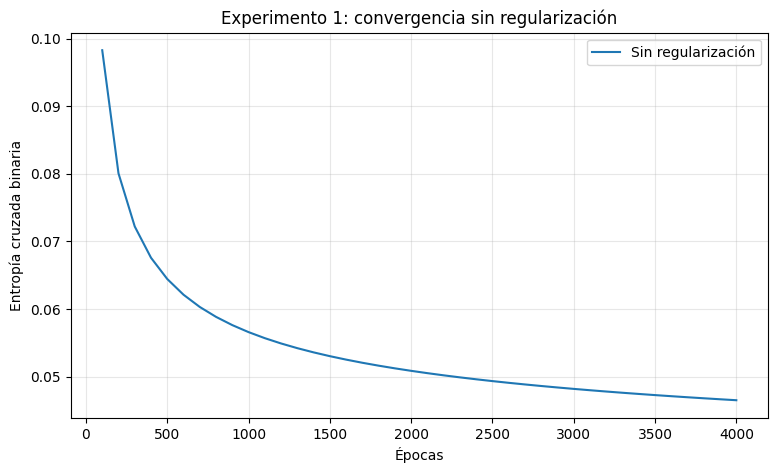

Pérdida final de entrenamiento: 0.04653


In [ ]:
LR = 0.1
EPOCAS = 4000
LAMBDA = 2.0

modelo_sin_reg = RegresionLogistica().fit(
    X_train_norm, y_train,
    lr=LR,
    epocas=EPOCAS,
    regularizacion=None,
    lam=0.0
)

plt.figure(figsize=(9, 5))
plt.plot(modelo_sin_reg.epochs_history, modelo_sin_reg.loss_history, label='Sin regularización')
plt.xlabel('Épocas')
plt.ylabel('Entropía cruzada binaria')
plt.title('Experimento 1: convergencia sin regularización')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print(f'Pérdida final de entrenamiento: {modelo_sin_reg.loss_history[-1]:.5f}')

### Tabla de al menos seis predicciones

La tabla selecciona ejemplos de ambas clases reales (hasta tres de cada clase, siempre que existan en el conjunto de prueba). `P(clase=1)` es la probabilidad de que el caso sea benigno; la confianza de la clase predicha es esa probabilidad si se predice benigno, o `1 - P(clase=1)` si se predice maligno.

In [ ]:
def tabla_predicciones(modelo, X_evaluar, y_real, max_por_clase=3):
    probabilidades = modelo.predict_proba(X_evaluar)
    predicciones = modelo.predict(X_evaluar)

    indices_elegidos = []
    for clase in [0, 1]:
        indices_clase = np.flatnonzero(y_real == clase)
        indices_elegidos.extend(indices_clase[:max_por_clase].tolist())
    indices_elegidos = sorted(set(indices_elegidos))

    p_clase_1 = probabilidades[indices_elegidos]
    y_pred = predicciones[indices_elegidos]
    confianza = np.where(y_pred == 1, p_clase_1, 1 - p_clase_1)

    return pd.DataFrame({
        'Índice en X_test': indices_elegidos,
        'Clase real': [nombre_clases[int(y_real[i])] for i in indices_elegidos],
        'Clase predicha': [nombre_clases[int(y_pred[j])] for j in range(len(indices_elegidos))],
        'P(clase=1: benigno)': p_clase_1,
        'Confianza de la predicción': confianza
    })

tabla_sin_reg = tabla_predicciones(modelo_sin_reg, X_test_norm, y_test)
display(tabla_sin_reg.style.format({'P(clase=1: benigno)': '{:.4f}', 'Confianza de la predicción': '{:.4f}'}))

print('Total de ejemplos mostrados:', len(tabla_sin_reg))

,Índice en X_test,Clase real,Clase predicha,P(clase=1: benigno),Confianza de la predicción
0,0,Maligno,Maligno,0.0000,1.0000
1,1,Benigno,Benigno,1.0000,1.0000
2,2,Maligno,Maligno,0.0018,0.9982
3,3,Benigno,Maligno,0.4784,0.5216
4,4,Maligno,Maligno,0.0000,1.0000
5,5,Benigno,Benigno,0.9968,0.9968


Total de ejemplos mostrados: 6


## 3.2. Experimento 2 — Regularización L1 y L2

Se entrenan dos modelos adicionales con los mismos datos, tasa de aprendizaje y número de épocas. La intensidad `lam` se establece en `2.00` para ambos, de modo que los resultados se puedan comparar bajo una misma escala de penalización.

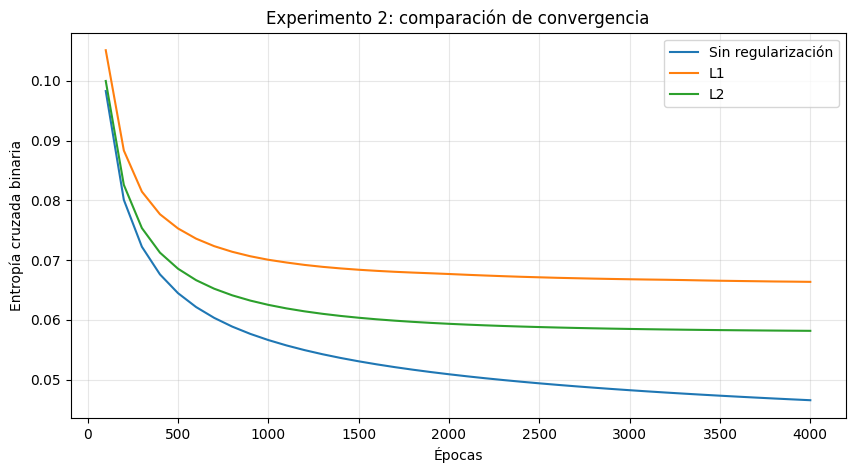

Pérdida final sin regularización: 0.04653
Pérdida final L1: 0.06634
Pérdida final L2: 0.05815


In [ ]:
modelo_l1 = RegresionLogistica().fit(
    X_train_norm, y_train,
    lr=LR,
    epocas=EPOCAS,
    regularizacion='L1',
    lam=LAMBDA
)

modelo_l2 = RegresionLogistica().fit(
    X_train_norm, y_train,
    lr=LR,
    epocas=EPOCAS,
    regularizacion='L2',
    lam=LAMBDA
)

# Una sola figura con las tres curvas de pérdida, según la práctica.
plt.figure(figsize=(10, 5))
plt.plot(modelo_sin_reg.epochs_history, modelo_sin_reg.loss_history, label='Sin regularización')
plt.plot(modelo_l1.epochs_history, modelo_l1.loss_history, label='L1')
plt.plot(modelo_l2.epochs_history, modelo_l2.loss_history, label='L2')
plt.xlabel('Épocas')
plt.ylabel('Entropía cruzada binaria')
plt.title('Experimento 2: comparación de convergencia')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print('Pérdida final sin regularización:', round(modelo_sin_reg.loss_history[-1], 5))
print('Pérdida final L1:', round(modelo_l1.loss_history[-1], 5))
print('Pérdida final L2:', round(modelo_l2.loss_history[-1], 5))

### Tablas de predicciones de los modelos L1 y L2

Se mantiene el mismo procedimiento de selección de casos para los dos modelos regularizados.

In [ ]:
tabla_l1 = tabla_predicciones(modelo_l1, X_test_norm, y_test)
tabla_l2 = tabla_predicciones(modelo_l2, X_test_norm, y_test)

print('Modelo con regularización L1')
display(tabla_l1.style.format({'P(clase=1: benigno)': '{:.4f}', 'Confianza de la predicción': '{:.4f}'}))

print('Modelo con regularización L2')
display(tabla_l2.style.format({'P(clase=1: benigno)': '{:.4f}', 'Confianza de la predicción': '{:.4f}'}))

Modelo con regularización L1


,Índice en X_test,Clase real,Clase predicha,P(clase=1: benigno),Confianza de la predicción
0,0,Maligno,Maligno,0.0000,1.0000
1,1,Benigno,Benigno,0.9999,0.9999
2,2,Maligno,Maligno,0.0198,0.9802
3,3,Benigno,Benigno,0.5125,0.5125
4,4,Maligno,Maligno,0.0000,1.0000
5,5,Benigno,Benigno,0.9805,0.9805


Modelo con regularización L2


,Índice en X_test,Clase real,Clase predicha,P(clase=1: benigno),Confianza de la predicción
0,0,Maligno,Maligno,0.0000,1.0000
1,1,Benigno,Benigno,1.0000,1.0000
2,2,Maligno,Maligno,0.0126,0.9874
3,3,Benigno,Benigno,0.5339,0.5339
4,4,Maligno,Maligno,0.0000,1.0000
5,5,Benigno,Benigno,0.9878,0.9878


## 3.3. Comparación de los tres modelos

Se evalúan los modelos sin regularización, L1 y L2 sobre el mismo conjunto de prueba. Se presenta una matriz de confusión por modelo, una tabla de métricas, una tabla de coeficientes `θ` y la evolución de los parámetros durante el entrenamiento.

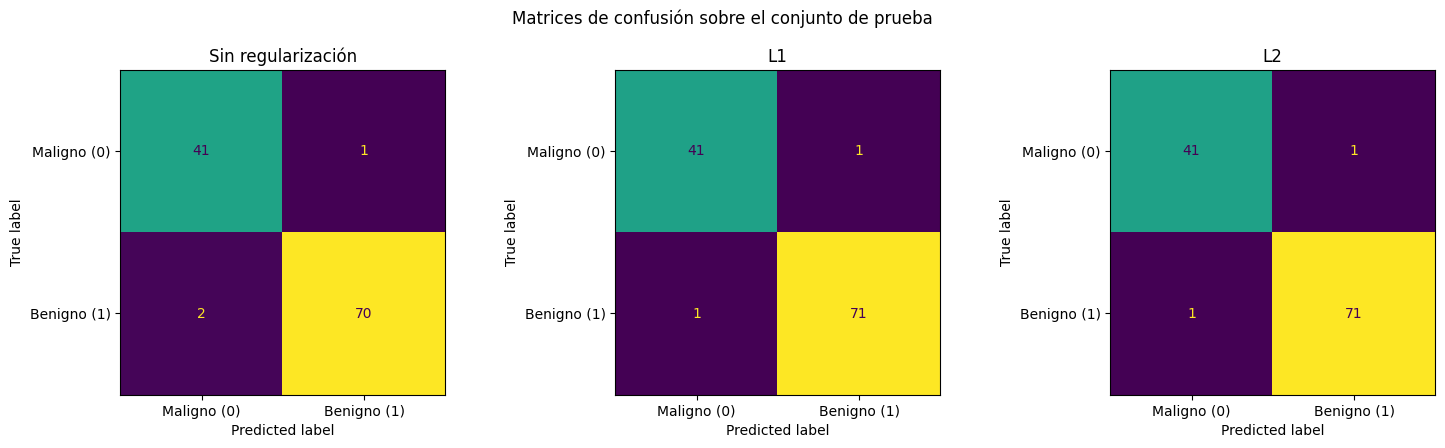

,Modelo,Exactitud,Precisión (maligno),Recall (maligno),F1-score (maligno),Precisión (benigno),Recall (benigno),F1-score (benigno)
0,Sin regularización,0.9737,0.9535,0.9762,0.9647,0.9859,0.9722,0.9790
1,L1,0.9825,0.9762,0.9762,0.9762,0.9861,0.9861,0.9861
2,L2,0.9825,0.9762,0.9762,0.9762,0.9861,0.9861,0.9861


In [ ]:
modelos = {
    'Sin regularización': modelo_sin_reg,
    'L1': modelo_l1,
    'L2': modelo_l2
}

# Tres matrices de confusión.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    y_pred = modelo.predict(X_test_norm)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Maligno (0)', 'Benigno (1)'])
    disp.plot(ax=ax, values_format='d', colorbar=False)
    ax.set_title(nombre)
plt.suptitle('Matrices de confusión sobre el conjunto de prueba')
plt.tight_layout()
plt.show()

# Tabla comparativa de métricas. La clase positiva para precision/recall/F1 es 1 (benigno).

# Tabla comparativa de métricas para ambas clases.
filas_metricas = []

for nombre, modelo in modelos.items():
    y_pred = modelo.predict(X_test_norm)

    filas_metricas.append({
        'Modelo': nombre,
        'Exactitud': accuracy_score(y_test, y_pred),

        # Métricas para la clase 0: maligno
        'Precisión (maligno)': precision_score(
            y_test, y_pred, pos_label=0, zero_division=0
        ),
        'Recall (maligno)': recall_score(
            y_test, y_pred, pos_label=0, zero_division=0
        ),
        'F1-score (maligno)': f1_score(
            y_test, y_pred, pos_label=0, zero_division=0
        ),

        # Métricas para la clase 1: benigno
        'Precisión (benigno)': precision_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        'Recall (benigno)': recall_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        'F1-score (benigno)': f1_score(
            y_test, y_pred, pos_label=1, zero_division=0
        )
    })

df_metricas = pd.DataFrame(filas_metricas)

display(
    df_metricas.style.format({
        col: '{:.4f}'
        for col in df_metricas.columns
        if col != 'Modelo'
    })
)


### Tabla comparativa de los parámetros `θ`

`θ₀` es el sesgo/intercepto y el resto de los valores corresponden a las características del dataset. Las características están normalizadas, por lo que estos coeficientes se interpretan en la escala Z-score.

In [ ]:
tabla_theta = pd.DataFrame({
    'Parámetro': ['theta_0 (sesgo)'] + nombres_caracteristicas,
    'Sin regularización': modelo_sin_reg.theta,
    'L1': modelo_l1.theta,
    'L2': modelo_l2.theta
})
display(tabla_theta.style.format({
    'Sin regularización': '{:.6f}',
    'L1': '{:.6f}',
    'L2': '{:.6f}'
}))

# Resumen de magnitud de los parámetros (sin incluir el sesgo).
resumen_pesos = []
for nombre, modelo in modelos.items():
    w = modelo.theta[1:]
    resumen_pesos.append({
        'Modelo': nombre,
        'Suma |theta| (L1)': np.sum(np.abs(w)),
        'Norma L2 de theta': np.linalg.norm(w),
        'Coeficientes con |theta| < 0.01': int(np.sum(np.abs(w) < 0.01))
    })
print('Resumen de magnitudes de los pesos (sin incluir el sesgo):')
display(pd.DataFrame(resumen_pesos).style.format({
    'Suma |theta| (L1)': '{:.4f}',
    'Norma L2 de theta': '{:.4f}'
}))

,Parámetro,Sin regularización,L1,L2
0,theta_0 (sesgo),0.274358,0.333561,0.401699
1,mean radius,-0.610332,-0.378489,-0.498761
2,mean texture,-0.748188,-0.397726,-0.584462
3,mean perimeter,-0.560804,-0.281373,-0.472144
4,mean area,-0.676045,-0.320125,-0.507706
5,mean smoothness,-0.267468,-0.000240,-0.215961
6,mean compactness,0.781194,0.000477,0.306017
7,mean concavity,-0.691346,-0.000270,-0.481877
8,mean concave points,-0.810475,-0.524601,-0.587212
9,mean symmetry,-0.160337,-0.000634,-0.181970


Resumen de magnitudes de los pesos (sin incluir el sesgo):


,Modelo,Suma |theta| (L1),Norma L2 de theta,Coeficientes con |theta| < 0.01
0,Sin regularización,21.8174,4.5476,0
1,L1,10.2939,2.7387,12
2,L2,14.1914,2.9212,0


### Evolución de los pesos `θ`

La figura contiene tres paneles, uno por modelo. Cada línea muestra la evolución de un parámetro guardado cada 100 épocas; la evolución del sesgo se muestra con línea discontinua.

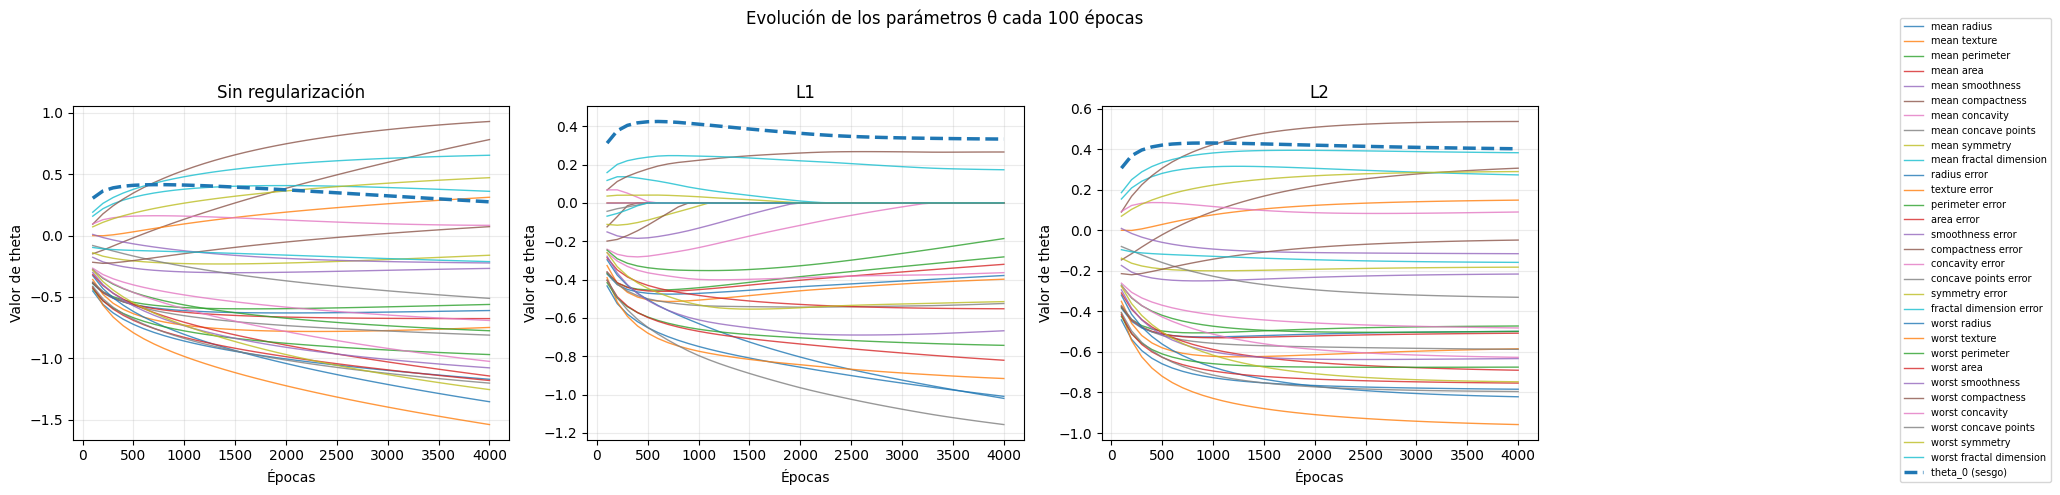

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5), sharey=False)
for ax, (nombre, modelo) in zip(axes, modelos.items()):
    historial = modelo.theta_history
    epocas_hist = modelo.epochs_history

    # La columna 0 es el sesgo; las restantes son los pesos de las características.
    for j, caracteristica in enumerate(nombres_caracteristicas, start=1):
        ax.plot(epocas_hist, historial[:, j], linewidth=1, alpha=0.8, label=caracteristica)
    ax.plot(epocas_hist, historial[:, 0], linestyle='--', linewidth=2.5, label='theta_0 (sesgo)')
    ax.set_title(nombre)
    ax.set_xlabel('Épocas')
    ax.set_ylabel('Valor de theta')
    ax.grid(True, alpha=0.25)

# Leyenda común fuera de los paneles para no reducir demasiado las gráficas.
handles, labels = axes[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=7, ncol=1)
fig.suptitle('Evolución de los parámetros θ cada 100 épocas')
fig.tight_layout(rect=[0, 0, 0.82, 0.93])
plt.show()


## 3.4. Preguntas de análisis

### 1. ¿La regularización tuvo algún efecto positivo en el desempeño? ¿Qué efecto tuvo cada norma en los parámetros θ?

En esta ejecución, la regularización tuvo un efecto positivo en el desempeño sobre el conjunto de prueba. El modelo sin regularización obtuvo una exactitud del 97.37 %, mientras que los modelos L1 y L2 alcanzaron el 98.25 %.

El modelo sin regularización obtuvo una precisión del 98.59 %, un recall del 97.22 % y un F1-score del 97.90 % para la clase positiva (benigno). En cambio, ambos modelos regularizados obtuvieron una precisión, un recall y un F1-score del 98.61 %.

Las matrices de confusión muestran que el modelo sin regularización clasificó correctamente 111 de las 114 muestras de prueba, mientras que L1 y L2 clasificaron correctamente 112. La mejora se debió a que los modelos regularizados clasificaron correctamente una muestra benigna adicional. Sin embargo, los tres modelos mantuvieron un caso maligno clasificado como benigno.

La regularización también modificó la magnitud de los parámetros θ. Sin regularización, la suma de los valores absolutos de los pesos fue 21.8174 y la norma L2 fue 4.5476. Con L1, estos valores disminuyeron a 10.2939 y 2.7387, respectivamente. Además, 12 coeficientes tuvieron una magnitud inferior a 0.01, lo que indica que varias características quedaron con una influencia muy pequeña en la clasificación.

Con L2, la suma de los valores absolutos fue 14.1914 y la norma L2 fue 2.9212. Ningún coeficiente tuvo una magnitud inferior a 0.01. Esto muestra que ambas normas redujeron la magnitud de los pesos, pero de maneras diferentes.

Las pérdidas finales de entrenamiento fueron 0.04653 sin regularización, 0.06634 con L1 y 0.05815 con L2. Aunque el modelo sin regularización obtuvo la menor pérdida de entrenamiento, los modelos regularizados consiguieron mejores métricas de clasificación sobre el conjunto de prueba. Esto muestra que una menor pérdida de entrenamiento no garantiza un mejor desempeño en datos nuevos.

**Conclusión:** en esta partición del dataset Breast Cancer Wisconsin, la regularización mejoró ligeramente la exactitud de prueba, del 97.37 % al 98.25 %. L1 redujo más la magnitud total de los pesos y produjo más coeficientes cercanos a cero, mientras que L2 redujo los pesos de forma más distribuida. Esta mejora corresponde a una única partición y no garantiza que la regularización siempre aumente la exactitud.

### 2. ¿Tomando en cuenta los resultados de cada modelo, existe alguna diferencia entre L1 y L2?

Sí. Aunque L1 y L2 obtuvieron las mismas métricas de clasificación y la misma matriz de confusión en esta ejecución, sus parámetros θ fueron diferentes.

L1 penaliza los valores absolutos de los pesos y favorece soluciones dispersas. En este experimento, 12 coeficientes tuvieron una magnitud inferior a 0.01 y la suma de los valores absolutos fue 10.2939. Esto indica que varias características adquirieron una influencia muy pequeña en el modelo.

L2 penaliza los cuadrados de los pesos y tiende a reducir sus magnitudes de forma más distribuida. En los resultados obtenidos, la suma de los valores absolutos fue 14.1914 y ninguno de los coeficientes tuvo una magnitud inferior a 0.01.

En cuanto al desempeño predictivo, ambos modelos alcanzaron una exactitud del 98.25 %, una precisión del 98.61 %, un recall del 98.61 % y un F1-score del 98.61 % para la clase benigna. Por tanto, no hubo diferencias en sus clasificaciones finales sobre el conjunto de prueba, aunque sí en la magnitud y distribución de sus parámetros.

**Conclusión:** L1 favoreció un modelo con varios coeficientes muy pequeños, mientras que L2 redujo los pesos sin producir la misma cantidad de coeficientes cercanos a cero. En esta ejecución, ambos modelos obtuvieron el mismo desempeño según las métricas evaluadas. Para determinar si alguno generaliza mejor de manera consistente, sería conveniente utilizar validación cruzada.
